
# Extended-phase-space integrators on learned dynamics

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/my-project.zip"
!rm -rf /content/project
!mkdir -p /content/project
!unzip -q "{ZIP_PATH}" -d /content/project
!find /content/project -maxdepth 2 -type d | head -20

Mounted at /content/drive
/content/project
/content/project/hamiltonian-dynamics-benchmark
/content/project/hamiltonian-dynamics-benchmark/.git
/content/project/hamiltonian-dynamics-benchmark/outputs
/content/project/hamiltonian-dynamics-benchmark/data
/content/project/hamiltonian-dynamics-benchmark/scripts
/content/project/hamiltonian-dynamics-benchmark/results
/content/project/hamiltonian-dynamics-benchmark/notebooks
/content/project/hamiltonian-dynamics-benchmark/src
/content/project/hamiltonian-dynamics-benchmark/.venv


In [4]:
import os
os.chdir("/content/project/hamiltonian-dynamics-benchmark")
print(os.listdir("."))

['.git', 'outputs', 'data', 'scripts', 'results', '.gitignore', 'notebooks', 'src', '.venv']


In [5]:
!pip install -q torch numpy scipy pandas matplotlib

In [6]:
!pip install -q geoopt torchdiffeq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 4.8 MB/s eta 0:00:00


In [7]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Could not find the project root containing the src folder.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: /content/project/hamiltonian-dynamics-benchmark


In [8]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from src.datasets.generate import generate_dataset
from src.datasets.systems.low_dim import (
    SimplePendulum, DoublePendulum, MassSpringSystem, HenonHeiles, FermiPastaUlamTsingou,
    SphericalPendulum, KeplerProblem, ChargedParticleMagneticTrap,
)

from src.datasets.systems.low_dim import CoupledOscillators
from src.datasets.integrators import midpoint, verlet
from src.integrators.explicit_extended_space import tao, pihajoki, tao_step, pihajoki_step
from src.integrators.semiexplicit_extended_space import semiexplicit, _compose, _strang, to_qpxy

warnings.filterwarnings("ignore")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "legend.fontsize": 8}
)

pd.set_option("display.float_format", "{:.3g}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## Configuration

In [9]:
SYSTEM_BUILDERS = {
    "simple_pendulum": lambda: SimplePendulum(),
    "double_pendulum": lambda: DoublePendulum(),
    "mass_spring": lambda: MassSpringSystem(),
    "henon_heiles": lambda: HenonHeiles(),
    "coupled_oscillators": lambda: CoupledOscillators(n=3),
    "fput": lambda: FermiPastaUlamTsingou(m=3, omega=50.0),
    "kepler":             lambda: KeplerProblem(dim=2),
    "charged_particle":   lambda: ChargedParticleMagneticTrap(dim=2),
    "spherical_pendulum": lambda: SphericalPendulum(),
}
SYSTEMS = list(SYSTEM_BUILDERS)
MAIN_SYSTEMS = ["double_pendulum"]

_DEFAULT = dict(
    T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
    roll_T=15.0, roll_steps=300,
    separable=True, chaotic=False, omega0=1.0, reversible=True,
)

SYSTEM_CFG = {k: dict(_DEFAULT) for k in SYSTEM_BUILDERS}
SYSTEM_CFG["double_pendulum"].update(
    T=20.0, steps=2000, T_err=5.0, conv_T=5.0,
    roll_T=5.0, roll_steps=250, separable=False, chaotic=True,
)

SYSTEM_CFG["henon_heiles"].update(
    T_err=20.0, conv_T=5.0, chaotic=True,
)

SYSTEM_CFG["fput"] = dict(_DEFAULT)
SYSTEM_CFG["fput"].update(T=10.0, steps=2000, T_err=10.0, conv_T=1.0,
                          separable=True, chaotic=False, omega0=5.0)

SYSTEM_CFG["kepler"].update(T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
                            separable=True, omega0=2.0)

SYSTEM_CFG["charged_particle"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                      separable=False, omega0=2.0, reversible=False)

SYSTEM_CFG["spherical_pendulum"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                        separable=False, omega0=1.0, roll_steps=600)

# ----------------------------------------------------------------------------
# True Dynamics part settings
# ----------------------------------------------------------------------------
N_TEST, SEED_TEST = 8, 123              # test trajectories per system (metrics: median over them)
CONV_STEPS = [5, 10, 20, 40, 80, 160, 320]  # step counts of the convergence / stability sweep (h = conv_T / n)
STAB_TOL = 0.5                          # "stable" = max drift < STAB_TOL * (1 + |H0|)
TAO_OMEGA_REL = 10.0                    # Tao omega used in the main comparison (x omega0)
OMEGAS_REL = [0.0, 1.0, 10.0, 100.0]    # Tao restraint sweep (x omega0)
FOCUS_SYSTEM = "double_pendulum"
POINCARE_T, POINCARE_STEPS, POINCARE_N = 400.0, 8000, 4

# ----------------------------------------------------------------------------
# Extended-space diagnostics settings
# ----------------------------------------------------------------------------
JO_KW = dict(composition="triple_jump", tol=1e-12, max_iter=100, solver="newton")
JO_TOLS = [1e-6, 1e-9, 1e-12, 1e-14]    # projection tolerance sweep (A6)
EXT_STRIDE_MAX = 400                    # max number of time samples for the extended H / momentum evaluations
SYMP_STATES = dict(n_traj=3, time_fracs=(0.0, 0.5, 1.0))   # states at which the extended symplectic defect is measured
COST_TARGET = 1e-3                      # error level used for the "cost to reach target accuracy" metric
INV_TOL = 1e-6                          # a candidate momentum counts as conserved if the reference solve keeps it this well

# ----------------------------------------------------------------------------
# Learned models part settings
# ----------------------------------------------------------------------------
QUICK_RUN = False                       # True: 3 systems, 30 epochs, 1 seed (smoke test, a few minutes)
RUN_LEARNED = True
LEARNED_SYSTEMS = list(MAIN_SYSTEMS)    # same five systems as the true-dynamics notebook, one model per system and seed
MODELS = ["HNN", "GeoHNN"]
TRAIN_SEEDS = [42, 43]                  # one dataset + one init per seed
N_TRAIN, TSPAN_TRAIN, STEPS_TRAIN = 40, (0.0, 10.0), 500
VAL_FRAC = 0.2                          # fraction of TRAJECTORIES held out for validation / early stopping
HIDDEN, EPOCHS, BATCH = 64, 300, 512
LR, LR_MIN, PATIENCE = 2e-3, 1e-5, 60   # cosine decay LR -> LR_MIN; early stop after PATIENCE epochs w/o val improvement
HORIZON_FACTORS = [1, 4]                # rollout horizons (x roll_T): 1 = standard, 4 = long-time behaviour
REF_RTOL, REF_ATOL = 1e-6, 1e-8         # tight reference solve of the learned field
FOCUS_MODEL = "GeoHNN"
LIMITED_THRESH = 0.5                    # (system, model) is "integrator-limited" if max int_err / model_err > this

RUN_ABLATION = True                     # focus system + focus model only
ABL_NTRAIN = [10, 40]
ABL_NOISE = [0.0, 0.05]                 # relative to the std of each state dimension
ABL_EPOCHS = [20, 100, EPOCHS]          # training-length ablation

if QUICK_RUN:
    LEARNED_SYSTEMS = ["double_pendulum", "henon_heiles", "spherical_pendulum"]
    TRAIN_SEEDS, EPOCHS, PATIENCE, N_TRAIN = [42], 30, 15, 20
    HORIZON_FACTORS, ABL_NTRAIN, ABL_EPOCHS = [1], [10, 20], [10, 30]

# ----------------------------------------------------------------------------
# Output
# ----------------------------------------------------------------------------
OUT = ROOT / "outputs" / "extended_phase_space"
OUT.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Methods: label -> (solver name, omega)
# ----------------------------------------------------------------------------
def methods_for(key, verlet=True):
    cfg = SYSTEM_CFG[key]
    m = {
        "Pihajoki": ("pihajoki", None),                 # mixing (alpha, beta) = (1, 0)
        "Pihajoki (0,0)": ("pihajoki00", None),        # symmetric mixing: symplectic in the extended space
        "Tao (order 2)": ("tao", TAO_OMEGA_REL * cfg["omega0"]),
        "Tao (order 4)": ("tao4", TAO_OMEGA_REL * cfg["omega0"]),
        "J-O (order 2)": ("jayawardana_ohsawa", None),
        "J-O (order 4)": ("jayawardana_ohsawa4", None),
        "Midpoint": ("midpoint", None),
        "RK4": ("rk4", None),
    }
    if verlet and cfg["separable"]:
        m["Verlet"] = ("verlet", None)
    return m


ALL_LABELS = list(dict.fromkeys(l for k in SYSTEMS for l in methods_for(k)))
BASELINES = {"Midpoint", "RK4", "Verlet"}
COLORS = {
    "Pihajoki": "tab:orange",
    "Pihajoki (0,0)": "gold",
    "Tao (order 2)": "tab:blue",
    "Tao (order 4)": "tab:pink",
    "J-O (order 2)": "tab:cyan",
    "J-O (order 4)": "tab:brown",
    "Midpoint": "tab:green",
    "RK4": "tab:red",
    "Verlet": "tab:purple",
}

def sty(label):
    return dict(color=COLORS.get(label), ls="--" if label in BASELINES else "-", lw=1.5)

## Load shared helpers

In [10]:
exec((ROOT / "notebooks" / "integrators" / "extended_phase_space" / "ext_common.py").read_text())   # integration, extended-space tools, metrics, plot helpers
print("shared helpers loaded from", ROOT / "src" / "ext_common.py")

shared helpers loaded from /content/project/hamiltonian-dynamics-benchmark/src/ext_common.py


## Training strategy: one model per system

In [11]:
props = pd.DataFrame({
    k: dict(dof=SYSTEM_BUILDERS[k]().state_dim // 2, separable=SYSTEM_CFG[k]["separable"],
            chaotic=SYSTEM_CFG[k]["chaotic"], reversible=SYSTEM_CFG[k].get("reversible", True),
            omega0=SYSTEM_CFG[k]["omega0"])
    for k in LEARNED_SYSTEMS}).T
display(props)

,dof,separable,chaotic,reversible,omega0
double_pendulum,2,False,True,True,1


## Training

In [12]:
import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found")
TRAIN_DEVICE = {"HNN": DEVICE, "GeoHNN": DEVICE}
from src.models.baselines import MLP, HNN, DoubleHeadHNN, CholeskyHNN
from src.models.geohnn import GeoHNN
from src.models.api import predict_derivative
from src.integrators.model_field import batched_field, model_vector_field


def build_model(name, state_dim):
    d = state_dim // 2
    return {
        "MLP": lambda: MLP(state_dim, HIDDEN),
        "HNN": lambda: HNN(state_dim, HIDDEN),
        "DoubleHeadHNN": lambda: DoubleHeadHNN(state_dim, HIDDEN),
        "CholeskyHNN": lambda: CholeskyHNN(state_dim, HIDDEN),
        "GeoHNN": lambda: GeoHNN(d),
    }[name]()


def time_idx(n):
    return np.unique(np.linspace(0, n, min(n + 1, EXT_STRIDE_MAX)).round().astype(int))


def _batched_loss(model, X, dX, batch):
    tot = 0.0
    for i in range(0, X.shape[0], batch):
        tot += ((predict_derivative(model, X[i:i + batch]) - dX[i:i + batch]) ** 2).sum().item()
    return tot / dX.numel()


def train_model(model, X, dX, epochs, batch, lr, seed=0, val=None, lr_min=None, patience=None, device=None):
    lr_min = LR_MIN if lr_min is None else lr_min
    patience = PATIENCE if patience is None else patience
    dev = DEVICE if device is None else device
    torch.manual_seed(seed)
    if dev.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    model.to(dev)
    X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    dX = torch.as_tensor(dX, dtype=torch.float32, device=dev)
    if val is not None:
        Xv, dXv = (torch.as_tensor(v, dtype=torch.float32, device=dev) for v in val)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1), eta_min=lr_min)
    n = X.shape[0]
    hist = dict(train=[], val=[], best_epoch=0, best_val=np.inf, epochs_run=0)
    best_state, wait = None, 0
    for ep in range(epochs):
        model.train()
        perm, tot = torch.randperm(n, device=dev), 0.0
        for i in range(0, n, batch):
            idx = perm[i : i + batch]
            loss = ((predict_derivative(model, X[idx]) - dX[idx]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        sched.step()
        hist["train"].append(tot / n)
        hist["epochs_run"] = ep + 1
        if val is None:
            continue
        model.eval()
        v = _batched_loss(model, Xv, dXv, batch)
        hist["val"].append(v)
        if v < hist["best_val"] * (1.0 - 1e-3):
            hist["best_val"], hist["best_epoch"], wait = v, ep, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    elif val is None:
        hist["best_epoch"] = hist["epochs_run"] - 1
    model.eval()
    model.cpu()
    return hist


def learned_hamiltonian(model, name):
    if name == "MLP":
        return None
    dtype = next(model.parameters()).dtype

    def H(X):
        x = torch.as_tensor(np.asarray(X), dtype=dtype)
        with torch.no_grad():
            if name == "GeoHNN":
                h = model.compute_hamiltonian(
                    x[:, : model.n_dof].contiguous(), x[:, model.n_dof :].contiguous()
                )[0]
            else:
                h = model(x)
        return h.reshape(-1).double().numpy()

    return H

Training device: cuda | Tesla T4


In [13]:
def learned_data(system, key, n_train, noise, train_seed):
    # training / validation arrays; the split is by TRAJECTORY so validation measures generalisation to unseen orbits
    D = system.state_dim
    data = generate_dataset(system, n_train, TSPAN_TRAIN, STEPS_TRAIN, seed=train_seed, system_key=key)
    X, dX = np.asarray(data["X"]), np.asarray(data["dX"])
    rng = np.random.default_rng(train_seed)
    nv = int(round(VAL_FRAC * n_train)) if n_train > 1 else 0
    if X.ndim == 3 and X.shape[0] == n_train:
        perm = rng.permutation(n_train)
        iv, it = perm[:nv], perm[nv:]
        Xt, Xv = X[it].reshape(-1, D), X[iv].reshape(-1, D)
        dXt, dXv = dX[it].reshape(-1, D), dX[iv].reshape(-1, D)
    else:  # fall back to a random sample-level split
        X, dX = X.reshape(-1, D), dX.reshape(-1, D)
        perm = rng.permutation(len(X))
        k = int(round(VAL_FRAC * len(X)))
        Xt, dXt, Xv, dXv = X[perm[k:]], dX[perm[k:]], X[perm[:k]], dX[perm[:k]]
    if noise > 0:  # measurement noise on the input states, relative to each dimension's std
        sd = Xt.std(0)
        Xt = Xt + noise * sd * rng.standard_normal(Xt.shape)
        Xv = Xv + noise * sd * rng.standard_normal(Xv.shape)
    return Xt, dXt, Xv, dXv

In [14]:
def run_learned(key, train_seed, n_train=None, noise=0.0, models=None, epochs=None, tag="main", horizons=None):
    n_train = N_TRAIN if n_train is None else n_train
    models = MODELS if models is None else models
    epochs = EPOCHS if epochs is None else epochs
    horizons = HORIZON_FACTORS if horizons is None else horizons
    cfg = SYSTEM_CFG[key]
    system = SYSTEM_BUILDERS[key]()
    D = system.state_dim
    d = D // 2
    Y0 = np.asarray(system.generate_initial_conditions(N_TEST, seed=SEED_TEST), float)
    f_true = oracle_field_batched(system, N_TEST, d)
    H_true = true_H_fn(system)

    HZ = {}
    for hf in horizons:
        T, n = cfg["roll_T"] * hf, cfg["roll_steps"] * hf
        HZ[hf] = dict(T=T, n=n, ref_truth=solve_reference(f_true, Y0, d, T, n, 1e-10, 1e-10))
    h1 = horizons[0]
    invs = detect_invariants(HZ[h1]["ref_truth"], d)
    inv = invs[0] if invs else None

    Xt, dXt, Xv, dXv = learned_data(system, key, n_train, noise, train_seed)
    methods = methods_for(key, verlet=False)
    ctx = dict(system=system, d=d, T=HZ[h1]["T"], n=HZ[h1]["n"], Y0=Y0, ref_truth=HZ[h1]["ref_truth"],
               models={}, hist={}, runs={}, ref_model={}, H_learned={}, ext={}, fit=[])
    rows = []
    for name in models:
        t0 = time.perf_counter()
        try:
            m = build_model(name, D)
            hist = train_model(m, Xt, dXt, epochs, BATCH, LR, seed=train_seed, val=(Xv, dXv),
                               device=TRAIN_DEVICE.get(name, DEVICE))
        except Exception as e:
            print(f"   {key}/{name}: training FAILED: {type(e).__name__}: {e}")
            continue
        t_train = time.perf_counter() - t0
        ctx["hist"][name] = hist
        ctx["fit"].append(dict(tag=tag, system=key, model=name, train_seed=train_seed, n_train=n_train, noise=noise,
                               epochs=epochs, epochs_run=hist["epochs_run"], best_epoch=hist["best_epoch"],
                               train_loss=hist["train"][hist["best_epoch"]], val_loss=hist["best_val"],
                               train_seconds=t_train))
        f_b, f_s = batched_field(m, N_TEST, d), model_vector_field(m)
        H_l = learned_hamiltonian(m, name)
        ctx["models"][name], ctx["H_learned"][name] = m, H_l
        for hf in horizons:
            T, n, ref_truth = HZ[hf]["T"], HZ[hf]["n"], HZ[hf]["ref_truth"]
            try:
                ref_m = solve_reference(f_b, Y0, d, T, n, REF_RTOL, REF_ATOL)
            except Exception as e:
                print(f"   {key}/{name}: reference solve of the learned field failed at x{hf} ({e}); skipping")
                continue
            runs = run_all(methods, Y0, d, T, n, f_b, f_s)
            model_err = mean_over_time(state_error(ref_m, ref_truth))
            if hf == h1:
                ctx["ref_model"][name], ctx["runs"][name] = ref_m, runs
            idx = time_idx(n)
            for label, r in runs.items():
                if r["traj"] is None:
                    continue
                nm, om = methods[label]
                e = ext_diagnostics(r, nm, om, N_TEST, d, n, H_fn=H_l)
                if hf == h1:
                    ctx["ext"].setdefault(name, {})[label] = e
                st = e["stats"] if e else {}
                rows.append(dict(
                    tag=tag, system=key, model=name, train_seed=train_seed, n_train=n_train, noise=noise,
                    epochs=epochs, horizon=hf, T=T, method=label,
                    int_err=mean_over_time(state_error(r["traj"], ref_m)),
                    truth_err=mean_over_time(state_error(r["traj"], ref_truth)),
                    model_err=model_err,
                    trueH_drift=max_over_time(energy_drift(H_true, r["traj"])),
                    learnedH_drift=(max_over_time(energy_drift(H_l, r["traj"])) if H_l is not None else np.nan),
                    mom_drift=(max_over_time(phys_invariant_drift(inv["fn"], r["traj"], idx)) if inv else np.nan),
                    extH_drift=(max_over_time(e["Hbar_drift"]) if e is not None and "Hbar_drift" in e else np.nan),
                    gap_max=max_over_time(e["gap"]) if e is not None else np.nan,
                    jo_iters=float(np.mean(st["iterations"])) if "iterations" in st else np.nan,
                    jo_nfail=float(st["n_not_converged"]) if "n_not_converged" in st else np.nan,
                    evals=r["evals"], seconds=r["seconds"],
                ))
        print(f"   {key:18s} seed {train_seed} {name:14s} train {hist['train'][hist['best_epoch']]:.2e}  "
              f"val {hist['best_val']:.2e}  best ep {hist['best_epoch'] + 1}/{hist['epochs_run']}  "
              f"({time.perf_counter() - t0:6.1f}s)")
    return rows, ctx

In [15]:
LEARNED, LEARNED_ROWS, FIT_ROWS = {}, [], []
if RUN_LEARNED:
    for key in LEARNED_SYSTEMS:
        for s in TRAIN_SEEDS:
            try:
                rows, ctx = run_learned(key, s)
            except Exception as e:
                print(f"   {key} seed {s}: FAILED: {type(e).__name__}: {e}")
                continue
            LEARNED_ROWS += rows
            FIT_ROWS += ctx["fit"]
            LEARNED[(key, s)] = ctx
    df_learned = pd.DataFrame(LEARNED_ROWS)
    df_learned.to_csv(OUT / "learned_all_rows.csv", index=False)
    df_fit = pd.DataFrame(FIT_ROWS)
    df_fit.to_csv(OUT / "learned_training_summary.csv", index=False)

   double_pendulum    seed 42 HNN            train 2.17e-04  val 4.00e-03  best ep 265/300  ( 232.2s)
   double_pendulum    seed 42 GeoHNN         train 3.42e-04  val 4.90e-04  best ep 298/300  (1108.2s)
   double_pendulum    seed 43 HNN            train 2.55e-04  val 1.93e-02  best ep 268/300  ( 229.0s)
   double_pendulum    seed 43 GeoHNN         train 5.64e-04  val 2.02e-03  best ep 266/300  (1123.8s)


Training summary (median over seeds)


train_loss  val_loss  best_epoch  epochs_run  train_seconds
system          model                                                              
double_pendulum GeoHNN    0.000453   0.00125         281         300            157
                HNN       0.000236    0.0116         266         300           41.4

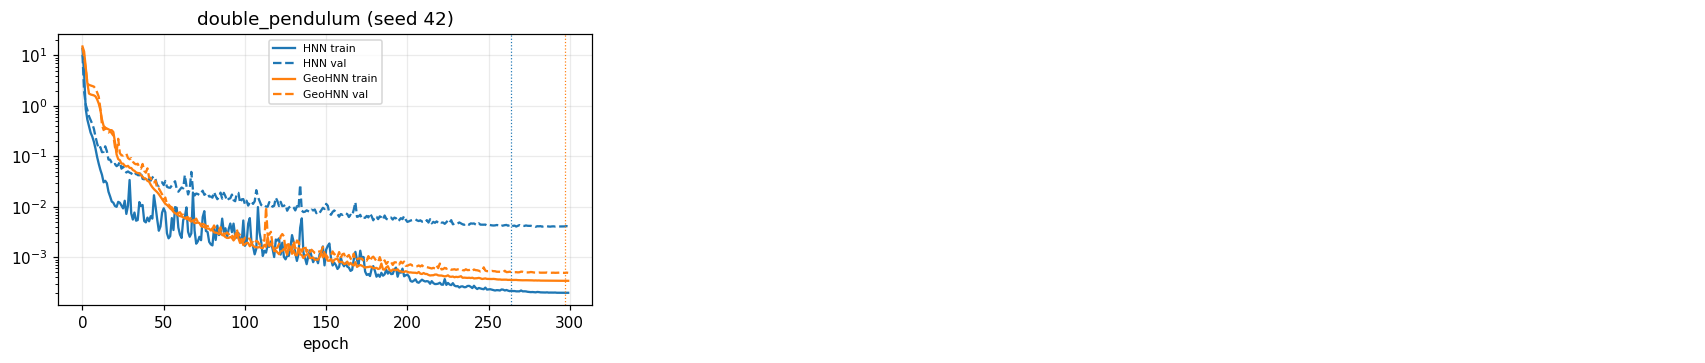

In [16]:
if RUN_LEARNED:
    print("Training summary (median over seeds)")
    display(df_fit.groupby(["system", "model"])[["train_loss", "val_loss", "best_epoch", "epochs_run", "train_seconds"]]
            .median().reindex(LEARNED_SYSTEMS, level=0).round(6))

    sys_l = [k for k in LEARNED_SYSTEMS if any(k == s for s, _ in LEARNED)]
    ncol = 3
    nrow = int(np.ceil(len(sys_l) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.4 * nrow), squeeze=False)
    for ax, key in zip(axes.ravel(), sys_l):
        ctx0 = LEARNED[(key, TRAIN_SEEDS[0])]
        for j, (name, h) in enumerate(ctx0["hist"].items()):
            ax.semilogy(h["train"], color=f"C{j}", label=f"{name} train")
            if h["val"]:
                ax.semilogy(h["val"], color=f"C{j}", ls="--", label=f"{name} val")
                ax.axvline(h["best_epoch"], color=f"C{j}", ls=":", lw=0.8)
        ax.set_title(f"{key} (seed {TRAIN_SEEDS[0]})")
        ax.set_xlabel("epoch")
    for ax in axes.ravel()[len(sys_l):]:
        ax.axis("off")
    axes[0, 0].legend(fontsize=7)
    plt.tight_layout()
    save(fig, "learned_training_curves")
    plt.show()

## Rollouts per system

In [17]:
if RUN_LEARNED:
    METRICS = ["int_err", "truth_err", "model_err", "trueH_drift", "learnedH_drift", "mom_drift",
               "extH_drift", "gap_max", "jo_iters", "jo_nfail", "evals"]
    HZ_MAIN, HZ_LONG = HORIZON_FACTORS[0], HORIZON_FACTORS[-1]
    dfm = df_learned.replace([np.inf, -np.inf], np.nan)
    agg_all = (dfm.groupby(["system", "model", "method", "horizon"])[METRICS].median().reset_index())
    agg_all.to_csv(OUT / "learned_summary.csv", index=False)
    agg = agg_all[agg_all["horizon"] == HZ_MAIN]
    agg_long = agg_all[agg_all["horizon"] == HZ_LONG] if HZ_LONG != HZ_MAIN else None
    print(f"Standard horizon (x{HZ_MAIN})")
    display(agg.drop(columns="horizon").round(4).set_index(["system", "model", "method"]))

Standard horizon (x1)


int_err  truth_err  model_err  trueH_drift  learnedH_drift  mom_drift  extH_drift  gap_max  jo_iters  jo_nfail  evals
system          model  method                                                                                                                               
double_pendulum GeoHNN J-O (order 2)    0.0031     0.0177     0.0182        0.011          0.0007        NaN      0.0014        0      7.23         0   24.7
                       J-O (order 4)    0.0001     0.0182     0.0182       0.0104               0        NaN           0        0      5.61         0   59.5
                       Midpoint         0.0062     0.0194     0.0182       0.0126          0.0014        NaN         NaN      NaN       NaN       NaN     12
                       Pihajoki          0.073     0.0774     0.0182        0.209           0.209        NaN      0.0174    0.265       NaN       NaN      4
                       Pihajoki (0,0)    0.665      0.666     0.0182         2.06            2.06        NaN       0.115     2.64       NaN       NaN      4
                       RK4                   0     0.0182     0.0182       0.0105               0        NaN         NaN      NaN       NaN       NaN      4
                       Tao (order 2)    0.0055     0.0212     0.0182       0.0382          0.0346        NaN      0.0014   0.0168       NaN       NaN      4
                       Tao (order 4)    0.0009     0.0182     0.0182       0.0158           0.006        NaN      0.0007   0.0023       NaN       NaN     12
                HNN    J-O (order 2)    0.0031     0.0212     0.0216       0.0191          0.0008        NaN      0.0015        0      7.23         0   24.7
                       J-O (order 4)    0.0001     0.0216     0.0216       0.0194               0        NaN           0        0      5.61         0   59.5
                       Midpoint         0.0061     0.0249     0.0216       0.0214          0.0015        NaN         NaN      NaN       NaN       NaN   12.2
                       Pihajoki         0.0716     0.0769     0.0216        0.209           0.212        NaN      0.0173    0.264       NaN       NaN      4
                       Pihajoki (0,0)     0.67      0.661     0.0216         2.06            2.06        NaN       0.118     2.64       NaN       NaN      4
                       RK4                   0     0.0216     0.0216       0.0193               0        NaN         NaN      NaN       NaN       NaN      4
                       Tao (order 2)    0.0054     0.0264     0.0216       0.0471          0.0344        NaN      0.0014   0.0167       NaN       NaN      4
                       Tao (order 4)    0.0009     0.0215     0.0216       0.0306           0.006        NaN      0.0007   0.0023       NaN       NaN     12

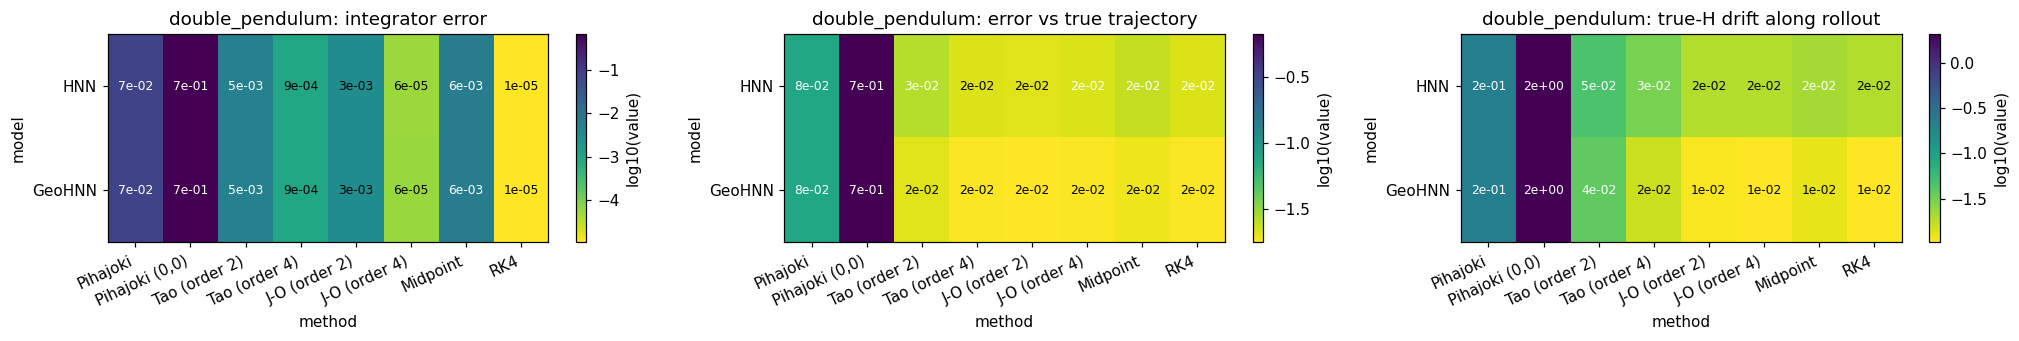

Long horizon (x4): truth_err is dominated by trajectory sensitivity on chaotic systems; int_err and the drifts remain meaningful.


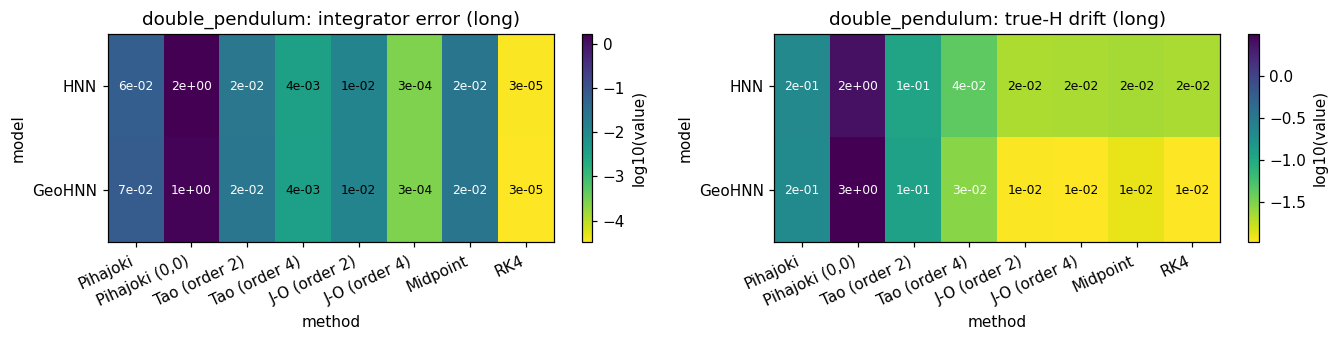

In [28]:
if RUN_LEARNED:
    sys_l = [k for k in LEARNED_SYSTEMS if k in set(agg["system"])]
    mod_l = [m for m in MODELS if m in set(agg["model"])]
    lab_l = list(methods_for(sys_l[0], verlet=False))

    def model_heatmaps(a, cols, fname):
        fig, axes = plt.subplots(len(sys_l), len(cols), figsize=(6.2 * len(cols), 2.6 * len(sys_l) + 0.6), squeeze=False)
        for row, key in enumerate(sys_l):
            sub = a[a["system"] == key]
            for ax, (col, title) in zip(axes[row], cols):
                heat(ax, piv(sub, col, rows="model", cols="method", ridx=mod_l, rcol=lab_l), f"{key}: {title}")
        plt.tight_layout()
        save(fig, fname)
        plt.show()

    model_heatmaps(agg, [("int_err", "integrator error"), ("truth_err", "error vs true trajectory"),
                         ("trueH_drift", "true-H drift along rollout")], "learned_heatmaps")
    if agg_long is not None:
        print(f"Long horizon (x{HZ_LONG}): truth_err is dominated by trajectory sensitivity on chaotic systems; "
              "int_err and the drifts remain meaningful.")
        model_heatmaps(agg_long, [("int_err", "integrator error (long)"), ("trueH_drift", "true-H drift (long)")], "learned_heatmaps_long")

## Cross-system comparison


Standard horizon (x1)


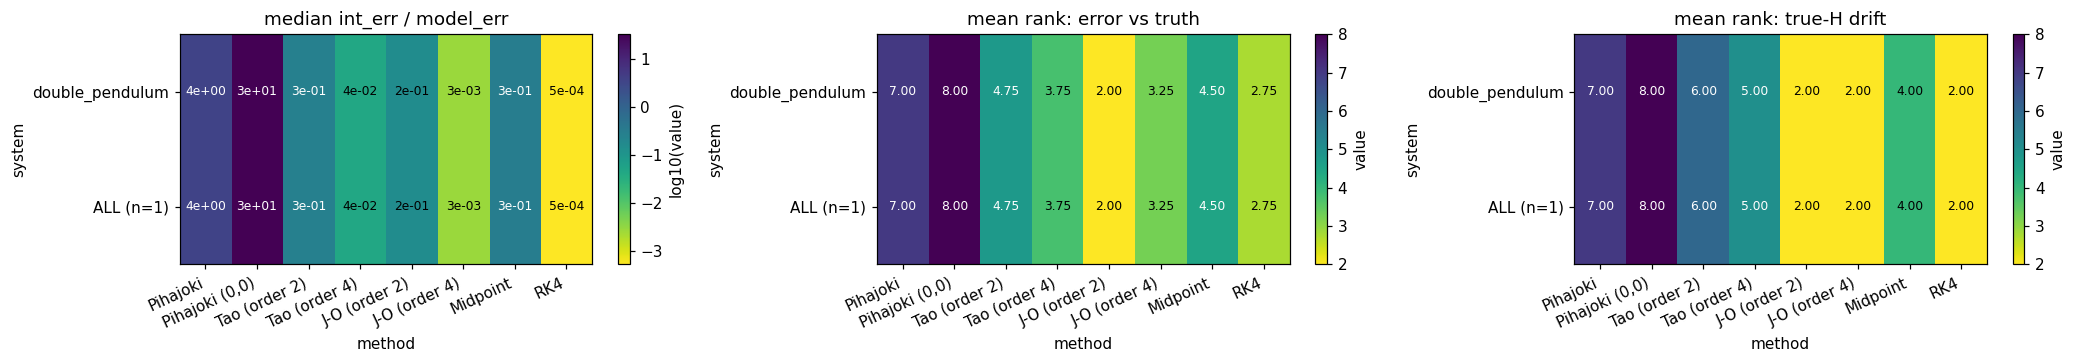

Long horizon (x4)


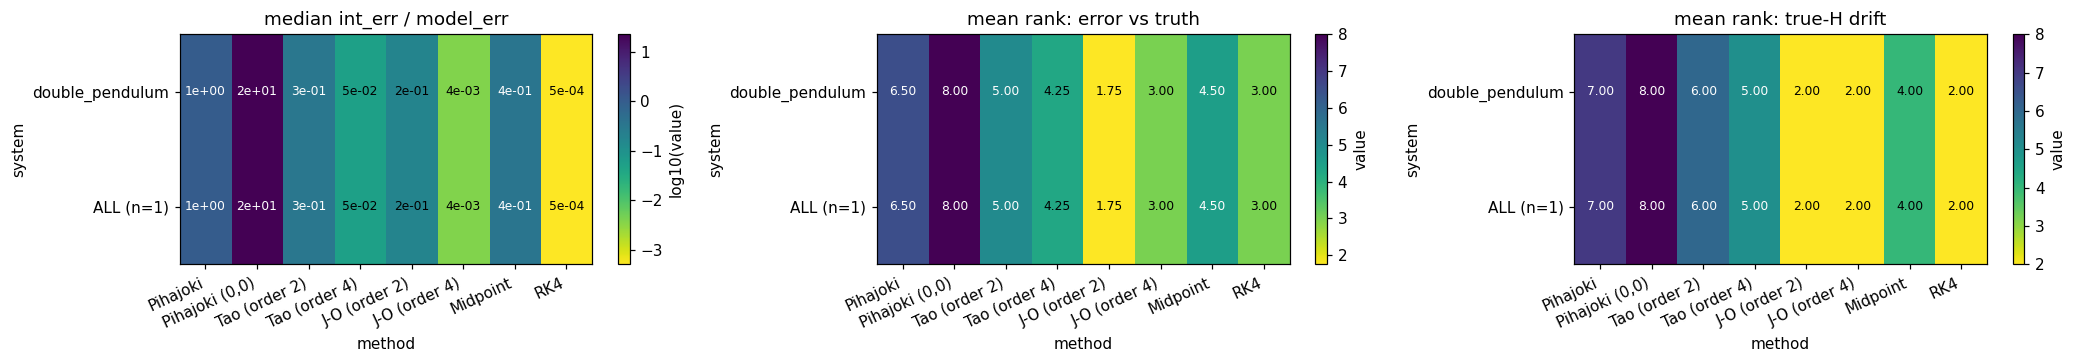

In [19]:
if RUN_LEARNED:
    cell = ["system", "model", "train_seed", "horizon"]
    dfm = df_learned.replace([np.inf, -np.inf], np.nan).copy()
    dfm["int_over_model"] = dfm["int_err"] / dfm["model_err"]
    for c in ("truth_err", "int_err", "trueH_drift"):
        dfm[f"rank_{c}"] = dfm.groupby(cell)[c].rank()
    dfm.to_csv(OUT / "learned_ranked_rows.csv", index=False)

    GMETRICS = [("int_over_model", "median int_err / model_err", True, "median"),
                ("rank_truth_err", "mean rank: error vs truth", False, "mean"),
                ("rank_trueH_drift", "mean rank: true-H drift", False, "mean")]

    def system_table(d, col, how):
        g = d.groupby(["system", "method"])[col].agg(how).unstack("method")
        g = g.reindex(index=[k for k in LEARNED_SYSTEMS if k in g.index], columns=lab_l)
        g.loc[f"ALL (n={len(g)})"] = d.groupby("method")[col].agg(how).reindex(lab_l)
        return g

    def system_figure(hz, fname):
        d = dfm[dfm["horizon"] == hz]
        fig, axes = plt.subplots(1, len(GMETRICS), figsize=(6.4 * len(GMETRICS), 0.6 * (len(sys_l) + 1) + 2.2),
                                 squeeze=False)
        for ax, (col, title, log, how) in zip(axes[0], GMETRICS):
            heat(ax, system_table(d, col, how), title, log=log, lower_is_better=True)
        plt.tight_layout()
        save(fig, fname)
        plt.show()

    print(f"Standard horizon (x{HZ_MAIN})")
    system_figure(HZ_MAIN, "learned_systems")
    if HZ_LONG != HZ_MAIN:
        print(f"Long horizon (x{HZ_LONG})")
        system_figure(HZ_LONG, "learned_systems_long")


In [20]:
if RUN_LEARNED:
    d = dfm[dfm["horizon"] == HZ_MAIN]
    rows = []
    for crit in ("rank_truth_err", "rank_int_err", "rank_trueH_drift"):
        t_ = system_table(d, crit, "mean")
        for s_, r in t_.iterrows():
            if r.notna().any():
                rows.append(dict(system=s_, criterion=crit.replace("rank_", ""),
                                 best=r.idxmin(), best_rank=r.min(), worst=r.idxmax(), worst_rank=r.max()))
    df_best = pd.DataFrame(rows)
    df_best.to_csv(OUT / "learned_winners.csv", index=False)
    display(df_best.set_index(["system", "criterion"]).round(2))


,,best,best_rank,worst,worst_rank
system,criterion,,,,
double_pendulum,truth_err,J-O (order 2),2,"Pihajoki (0,0)",8
ALL (n=1),truth_err,J-O (order 2),2,"Pihajoki (0,0)",8
double_pendulum,int_err,RK4,1,"Pihajoki (0,0)",8
ALL (n=1),int_err,RK4,1,"Pihajoki (0,0)",8
double_pendulum,trueH_drift,J-O (order 2),2,"Pihajoki (0,0)",8
ALL (n=1),trueH_drift,J-O (order 2),2,"Pihajoki (0,0)",8


## Error decomposition

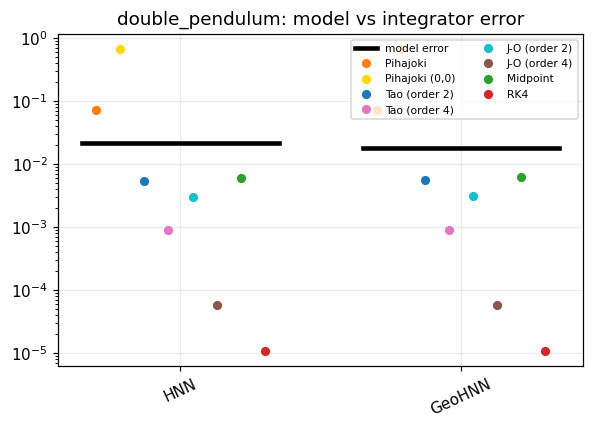

max_int_over_model > 1  =>  the integrator error exceeds the model error for at least one method


model_err    best_method  best_truth_err    worst_method  worst_truth_err  worst_over_best  max_int_over_model  integrator_limited
system          model                                                                                                                                     
double_pendulum GeoHNN     0.0182  J-O (order 2)          0.0177  Pihajoki (0,0)            0.666             37.6                36.6                True
                HNN        0.0216  J-O (order 2)          0.0212  Pihajoki (0,0)            0.661             31.2                  31                True

integrator-limited share (all systems):


,mean,count
model,,
GeoHNN,1,1
HNN,1,1


In [21]:
if RUN_LEARNED:
    ncol_ = min(3, len(sys_l))
    nrow_ = int(np.ceil(len(sys_l) / ncol_))
    fig, axes = plt.subplots(nrow_, ncol_, figsize=(5.5 * ncol_, 4 * nrow_), squeeze=False)
    for ax, key in zip(axes.ravel(), sys_l):
        sub = agg[agg["system"] == key]
        for i, m in enumerate(mod_l):
            g = sub[sub["model"] == m]
            if g.empty:
                continue
            ax.plot([i - 0.35, i + 0.35], [g["model_err"].iloc[0]] * 2, color="k", lw=3,
                    label="model error" if i == 0 else None)
            for j, lab in enumerate(lab_l):
                v = g.loc[g["method"] == lab, "int_err"]
                if len(v) and np.isfinite(v.iloc[0]):
                    ax.plot(i - 0.3 + 0.6 * j / max(len(lab_l) - 1, 1), v.iloc[0], "o",
                            color=COLORS.get(lab), ms=5, label=lab if i == 0 else None)
        ax.set_yscale("log")
        ax.set_xticks(range(len(mod_l)), mod_l, rotation=25)
        ax.set_title(f"{key}: model vs integrator error")
    for ax in axes.ravel()[len(sys_l):]:
        ax.axis("off")
    axes[0, 0].legend(ncol=2, fontsize=7)
    plt.tight_layout()
    save(fig, "learned_decomposition")
    plt.show()

    rows = []
    for (s, m), g in agg.groupby(["system", "model"]):
        g = g.replace([np.inf, -np.inf], np.nan).dropna(subset=["truth_err"])
        if g.empty:
            continue
        b, w = g.loc[g["truth_err"].idxmin()], g.loc[g["truth_err"].idxmax()]
        rows.append(dict(
            system=s, model=m, model_err=g["model_err"].iloc[0],
            best_method=b["method"], best_truth_err=b["truth_err"],
            worst_method=w["method"], worst_truth_err=w["truth_err"],
            worst_over_best=w["truth_err"] / b["truth_err"],
            max_int_over_model=g["int_err"].max() / g["model_err"].iloc[0],
            integrator_limited=bool(g["int_err"].max() / g["model_err"].iloc[0] > LIMITED_THRESH),
        ))
    df_dec = pd.DataFrame(rows)
    df_dec.to_csv(OUT / "learned_decomposition.csv", index=False)
    print("max_int_over_model > 1  =>  the integrator error exceeds the model error for at least one method")
    display(df_dec.round(4).set_index(["system", "model"]))

    print("integrator-limited share (all systems):")
    display(df_dec.groupby("model")["integrator_limited"].agg(["mean", "count"]).round(2))

## Extended-space diagnostics on the learned fields

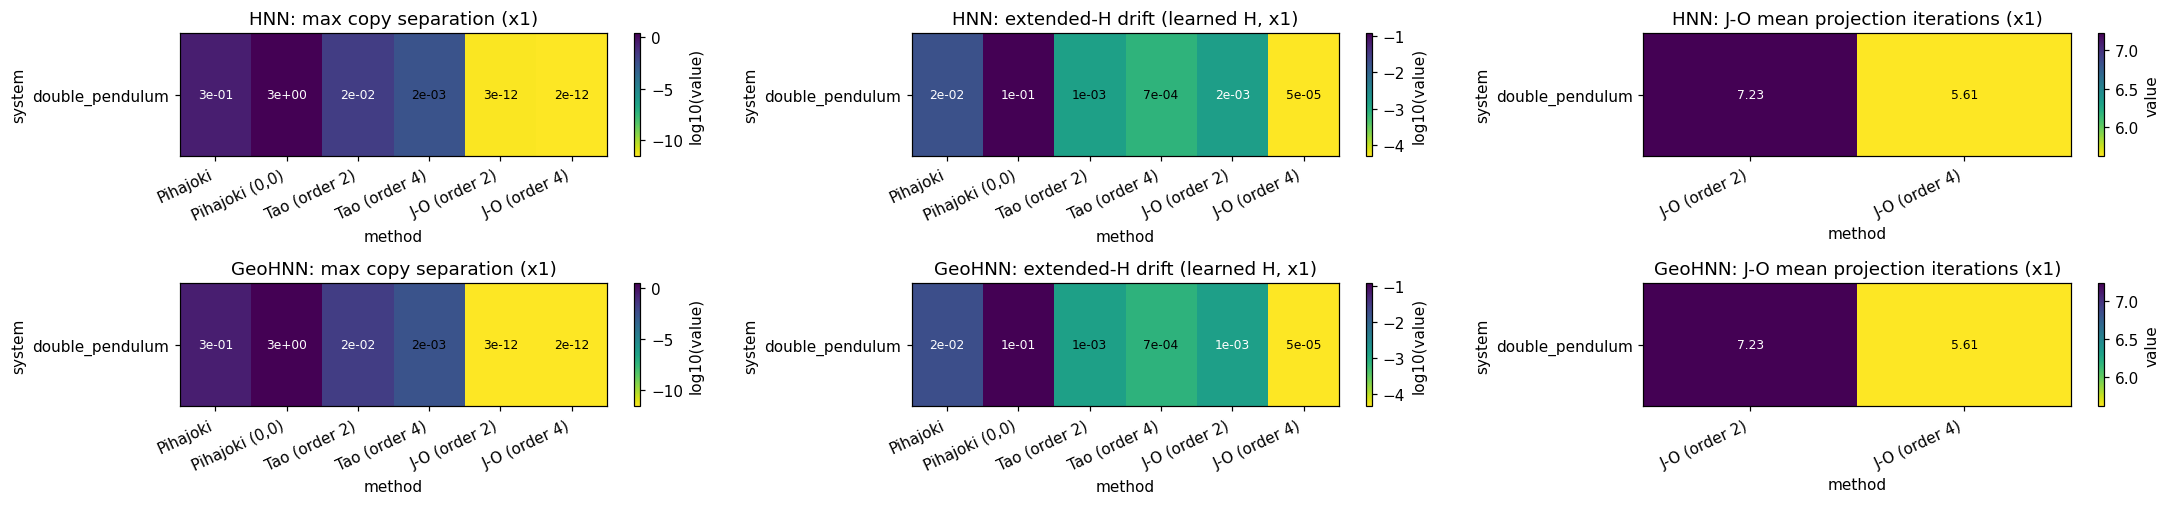

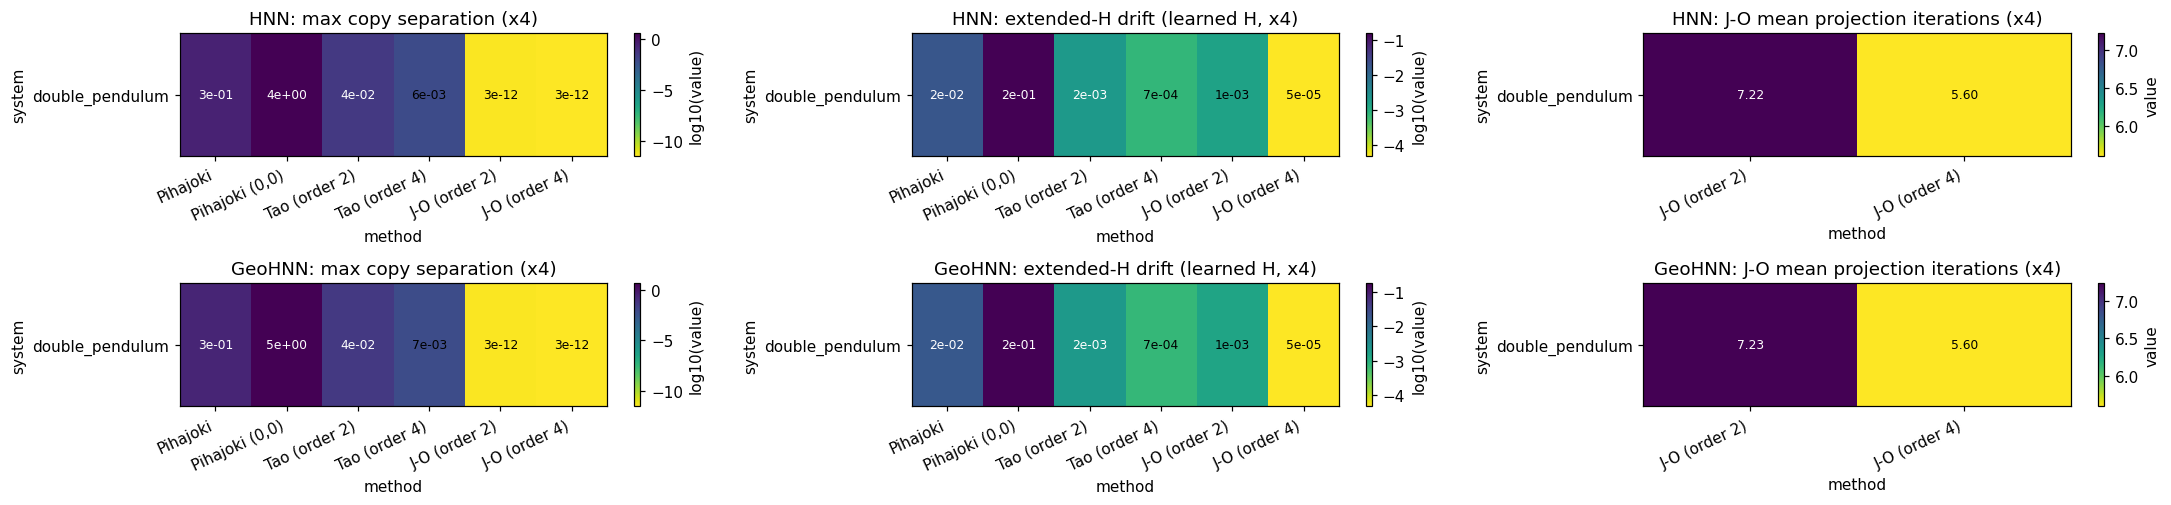

Total J-O steps that hit max_iter (summed over systems, standard + long horizons):


steps not converged
model  method                             
GeoHNN J-O (order 2)                     0
       J-O (order 4)                     0
       Midpoint                          0
       Pihajoki                          0
       Pihajoki (0,0)                    0
       RK4                               0
       Tao (order 2)                     0
       Tao (order 4)                     0
HNN    J-O (order 2)                     0
       J-O (order 4)                     0
       Midpoint                          0
       Pihajoki                          0
       Pihajoki (0,0)                    0
       RK4                               0
       Tao (order 2)                     0
       Tao (order 4)                     0

In [22]:
if RUN_LEARNED:
    EXT_L = [l for l in lab_l if methods_for(sys_l[0], verlet=False)[l][0] in EXT_NAMES]
    JO_L = [l for l in lab_l if methods_for(sys_l[0], verlet=False)[l][0] in JO_NAMES]
    for hz in dict.fromkeys([HZ_MAIN, HZ_LONG]):
        a = agg_all[agg_all["horizon"] == hz]
        fig, axes = plt.subplots(len(mod_l), 3, figsize=(20, (0.55 * len(sys_l) + 1.8) * len(mod_l)), squeeze=False)
        for r_, mname in enumerate(mod_l):
            sub = a[a["model"] == mname]
            heat(axes[r_, 0], piv(sub, "gap_max", rows="system", cols="method", ridx=sys_l, rcol=EXT_L),
                 f"{mname}: max copy separation (x{hz})")
            heat(axes[r_, 1], piv(sub, "extH_drift", rows="system", cols="method", ridx=sys_l, rcol=EXT_L),
                 f"{mname}: extended-H drift (learned H, x{hz})")
            heat(axes[r_, 2], piv(sub, "jo_iters", rows="system", cols="method", ridx=sys_l, rcol=JO_L),
                 f"{mname}: J-O mean projection iterations (x{hz})", log=False)
        plt.tight_layout()
        save(fig, f"learned_extended_x{hz}")
        plt.show()

    nf = agg_all.groupby(["model", "method"])["jo_nfail"].sum().dropna()
    print("Total J-O steps that hit max_iter (summed over systems, standard + long horizons):")
    display(nf.to_frame("steps not converged"))

## Zoom on one system and one model

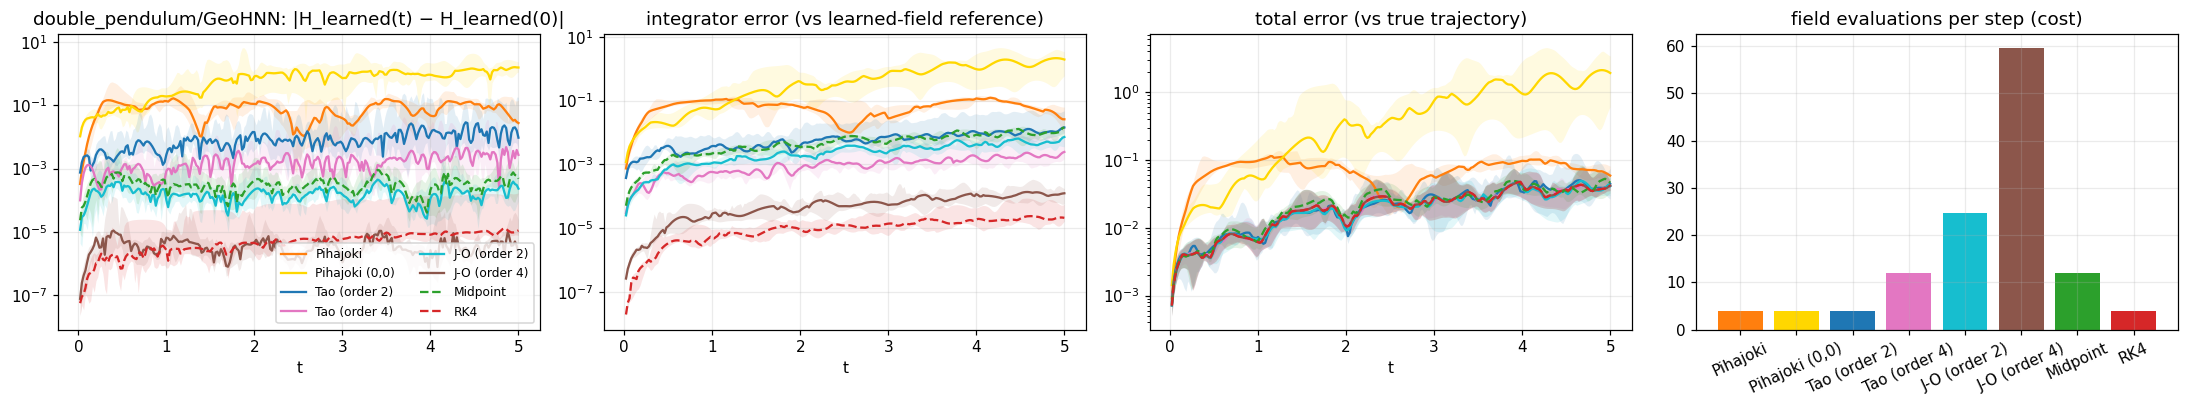

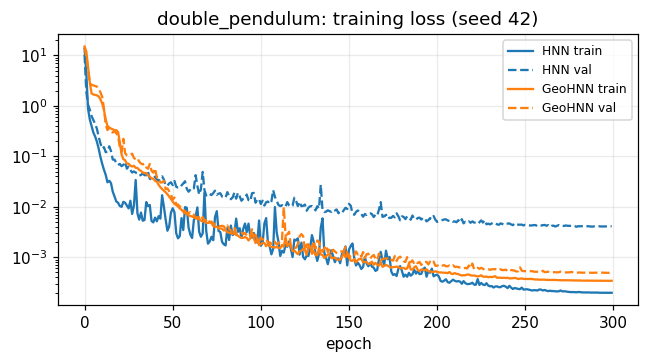

In [23]:
if RUN_LEARNED:
    fk = FOCUS_SYSTEM if FOCUS_SYSTEM in LEARNED_SYSTEMS else LEARNED_SYSTEMS[0]
    ctx = LEARNED[(fk, TRAIN_SEEDS[0])]
    fm = FOCUS_MODEL if FOCUS_MODEL in ctx["runs"] else next(iter(ctx["runs"]))
    tt = np.linspace(0, ctx["T"], ctx["n"] + 1)
    H_l = ctx["H_learned"][fm]
    fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
    for label, r in ctx["runs"][fm].items():
        if r["traj"] is None:
            continue
        if H_l is not None:
            band(axes[0], tt, energy_drift(H_l, r["traj"]), label)
        band(axes[1], tt, state_error(r["traj"], ctx["ref_model"][fm]), label)
        band(axes[2], tt, state_error(r["traj"], ctx["ref_truth"]), label)
    labels = [l for l, r in ctx["runs"][fm].items() if r["traj"] is not None]
    axes[3].bar(labels, [ctx["runs"][fm][l]["evals"] for l in labels],
                color=[COLORS[l] for l in labels])
    axes[3].tick_params(axis="x", rotation=25)
    axes[0].set_title(f"{fk}/{fm}: |H_learned(t) − H_learned(0)|")
    axes[1].set_title("integrator error (vs learned-field reference)")
    axes[2].set_title("total error (vs true trajectory)")
    axes[3].set_title("field evaluations per step (cost)")
    for ax in axes[:3]:
        ax.set_xlabel("t")
    axes[0].legend(ncol=2)
    plt.tight_layout()
    save(fig, "learned_focus")
    plt.show()

    # training curves of every model
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for j, (name, h) in enumerate(ctx["hist"].items()):
        ax.semilogy(h["train"], color=f"C{j}", label=f"{name} train")
        if h["val"]:
            ax.semilogy(h["val"], color=f"C{j}", ls="--", label=f"{name} val")
    ax.set_xlabel("epoch")
    ax.set_title(f"{fk}: training loss (seed {TRAIN_SEEDS[0]})")
    ax.legend()
    plt.tight_layout()
    plt.show()

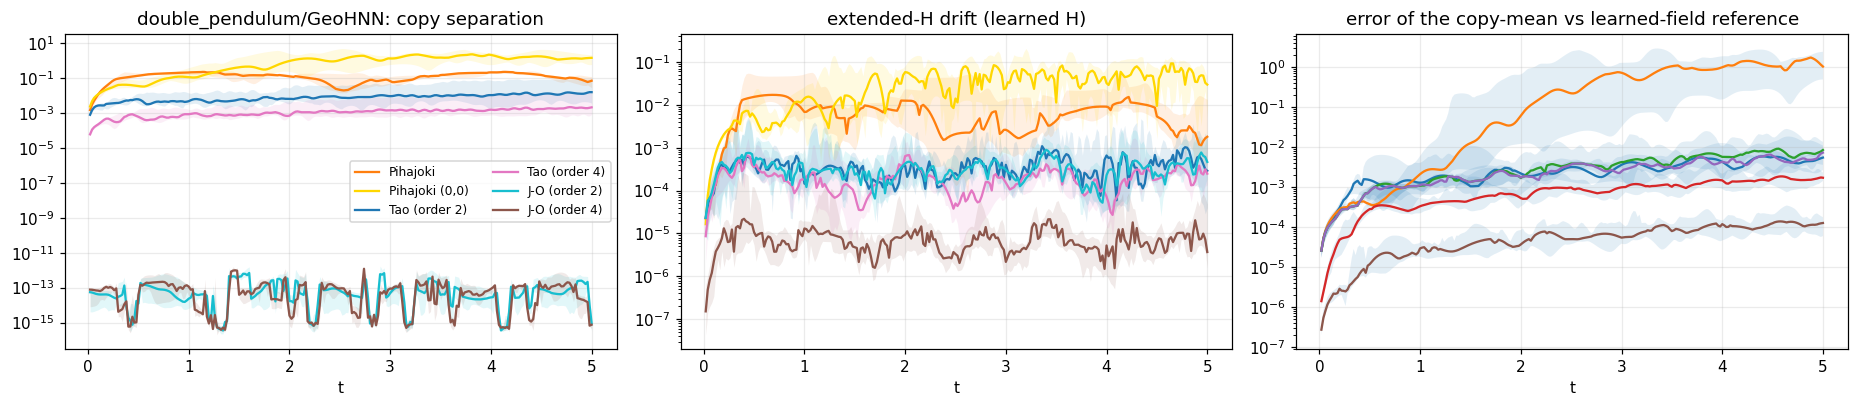

In [24]:
# Extended-space view of the focus rollout: copy separation and extended-H drift of the learned model
if RUN_LEARNED:
    ex = ctx["ext"].get(fm, {})
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for label, e in ex.items():
        if e is None:
            continue
        band(axes[0], tt, e["gap"], label)
        if "Hbar_drift" in e:
            band(axes[1], tt[e["idx"]], e["Hbar_drift"], label)
        if label in ctx["runs"][fm] and ctx["runs"][fm][label]["traj"] is not None:
            band(axes[2], tt, state_error(e["mean"], ctx["ref_model"][fm]), label + " (mean of copies)")
    axes[0].set_title(f"{fk}/{fm}: copy separation")
    axes[1].set_title("extended-H drift (learned H)")
    axes[2].set_title("error of the copy-mean vs learned-field reference")
    for ax in axes:
        ax.set_xlabel("t")
    axes[0].legend(ncol=2)
    plt.tight_layout()
    save(fig, "learned_focus_extended")
    plt.show()

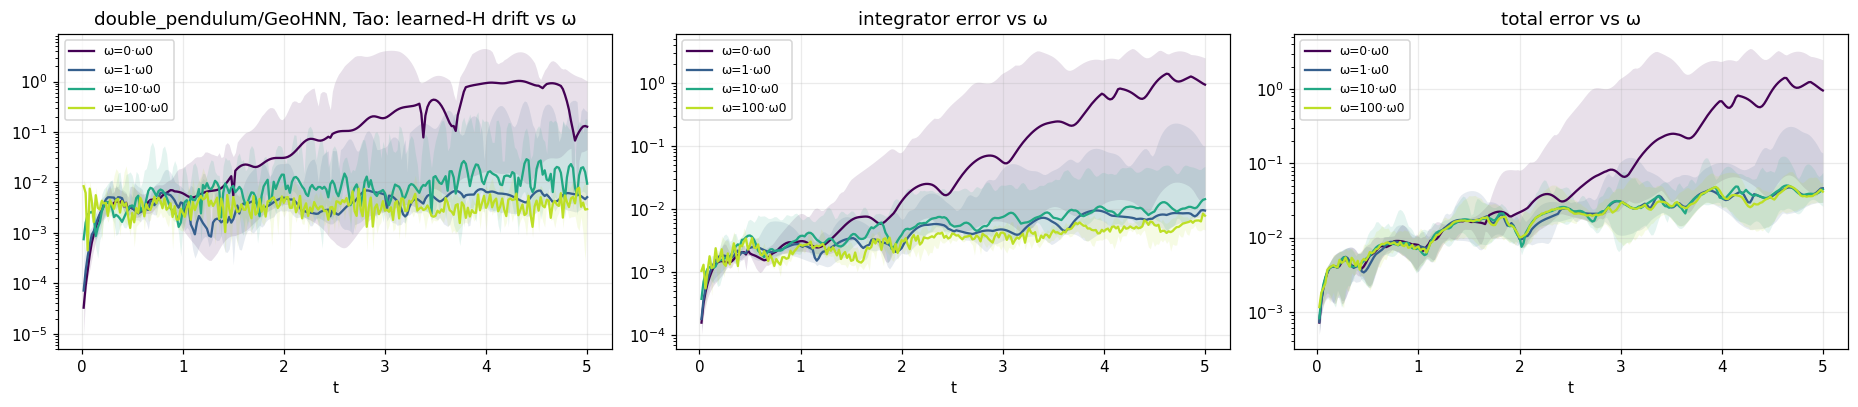

In [25]:
# Tao restraint omega on the focus model
if RUN_LEARNED:
    system, d, cfg = ctx["system"], ctx["d"], SYSTEM_CFG[fk]
    m = ctx["models"][fm]
    f_b, f_s = batched_field(m, N_TEST, d), model_vector_field(m)
    RUN_OM_M = run_all(
        {f"ω={w:g}·ω0": ("tao", w * cfg["omega0"]) for w in OMEGAS_REL},
        ctx["Y0"], d, ctx["T"], ctx["n"], f_b, f_s,
    )
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(RUN_OM_M)))
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for c, (label, r) in zip(cmap, RUN_OM_M.items()):
        if r["traj"] is None:
            continue
        if H_l is not None:
            band(axes[0], tt, energy_drift(H_l, r["traj"]), label, color=c, ls="-")
        band(axes[1], tt, state_error(r["traj"], ctx["ref_model"][fm]), label, color=c, ls="-")
        band(axes[2], tt, state_error(r["traj"], ctx["ref_truth"]), label, color=c, ls="-")
    axes[0].set_title(f"{fk}/{fm}, Tao: learned-H drift vs ω")
    axes[1].set_title("integrator error vs ω")
    axes[2].set_title("total error vs ω")
    for ax in axes:
        ax.set_xlabel("t")
        ax.legend()
    plt.tight_layout()
    save(fig, "learned_tao_omega")
    plt.show()